In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
df = pd.read_csv('netflix.csv', encoding='latin1')

In [11]:
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [12]:
df.shape

(8790, 10)

In [15]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
country,0
date_added,0
release_year,0
rating,0
duration,0
listed_in,0


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB


In [17]:
# 1. تحويل عمود التاريخ (date_added) من نص (object) إلى تاريخ (datetime)
# نستخدم errors='coerce' لتعامل سلس مع أي صيغ غير متوقعة
df['date_added'] = pd.to_datetime(df['date_added'].str.strip(), errors='coerce')

# 2. تحويل الأعمدة الفئوية (Categorical Columns) لتوفير الذاكرة وتسريع العمليات
categorical_cols = ['type', 'rating', 'country']
for col in categorical_cols:
    df[col] = df[col].astype('category')

# 3. التأكد من النمط الجديد للبيانات بعد التحويل
print("--- Data Types After Conversion ---")
print(df.dtypes)

--- Data Types After Conversion ---
show_id                 object
type                  category
title                   object
director                object
country               category
date_added      datetime64[ns]
release_year             int64
rating                category
duration                object
listed_in               object
dtype: object


In [18]:
# سننشئ عمودين جديدين: عمود للرقم وعمود للنوع (Minutes أو Seasons)
df['duration_int'] = df['duration'].str.extract('(\d+)').astype(float)

# عرض عينة للتأكد من نجاح العملية
display(df[['title', 'duration', 'duration_int']].head())

<>:2: SyntaxWarning: invalid escape sequence '\d'
<>:2: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_1411/3660276793.py:2: SyntaxWarning: invalid escape sequence '\d'
  df['duration_int'] = df['duration'].str.extract('(\d+)').astype(float)


,title,duration,duration_int
0,Dick Johnson Is Dead,90 min,90.0
1,Ganglands,1 Season,1.0
2,Midnight Mass,1 Season,1.0
3,Confessions of an Invisible Girl,91 min,91.0
4,Sankofa,125 min,125.0


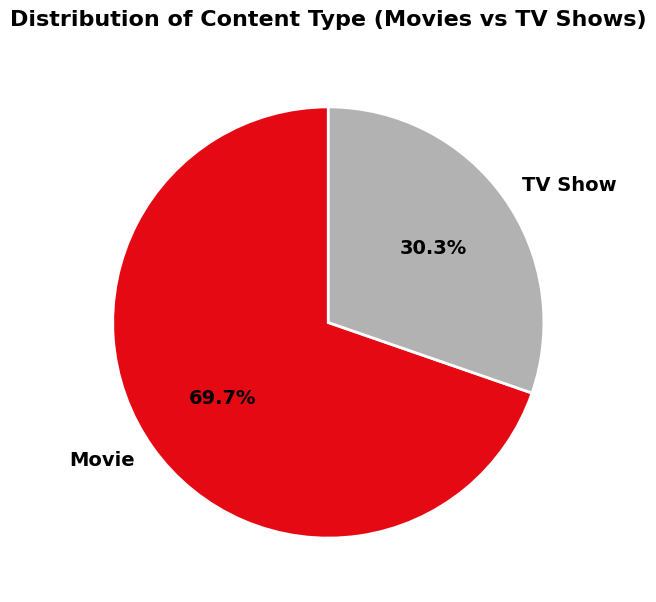

In [28]:
plt.figure(figsize=(7, 7))
type_counts = df['type'].value_counts()
# استخدام أحمر نتفليكس ولون رمادي فاتح وجميل عشان الكتابة السوداء تبان عليه بوضوح
colors = ['#e50914', '#b2b2b2']

plt.pie(type_counts, labels=type_counts.index, autopct='%1.1f%%', startangle=90, colors=colors,
        textprops={'fontsize': 14, 'weight': 'bold', 'color': 'black'},
        wedgeprops={'edgecolor': 'white', 'linewidth': 2})

plt.title('Distribution of Content Type (Movies vs TV Shows)', fontsize=16, weight='bold', pad=20)
plt.show()

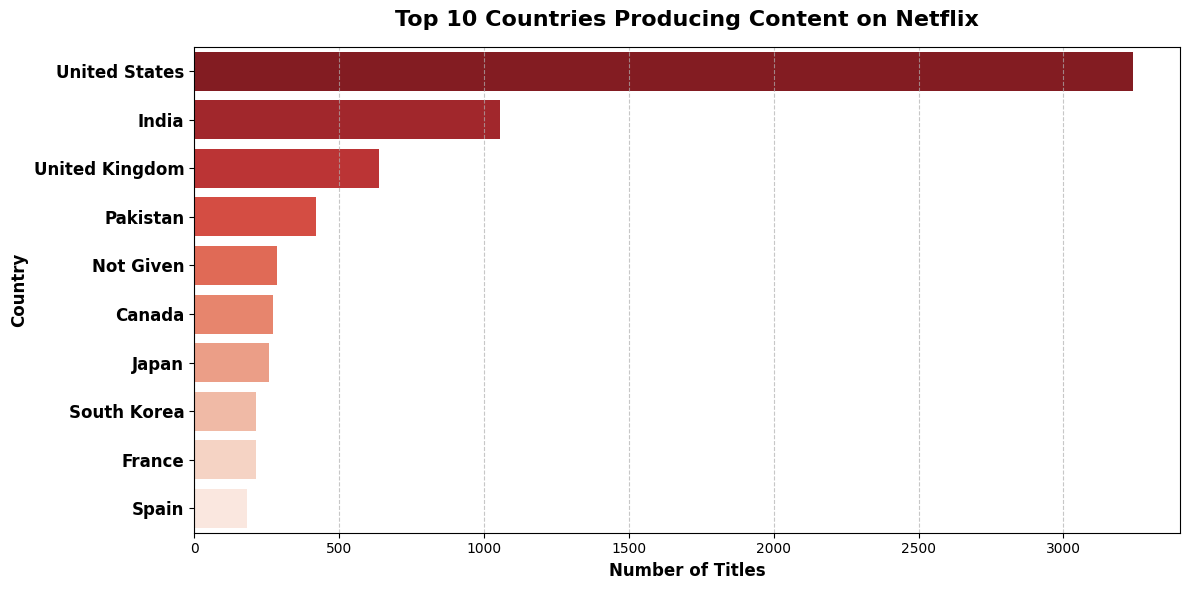

In [31]:
plt.figure(figsize=(12, 6))

# فصل الدول لو كانت مدمجة بفاصلة وحساب تكرار كل دولة على حدة
countries_series = df[df['country'] != 'Unknown']['country'].dropna().str.split(', ').explode()
top_countries = countries_series.value_counts().head(10)

sns.barplot(x=top_countries.values, y=top_countries.index, palette='Reds_r', hue=top_countries.index, legend=False)

plt.title('Top 10 Countries Producing Content on Netflix', fontsize=16, weight='bold', pad=15)
plt.xlabel('Number of Titles', fontsize=12, weight='bold')
plt.ylabel('Country', fontsize=12, weight='bold')
plt.xticks(fontsize=10)
plt.yticks(fontsize=12, weight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

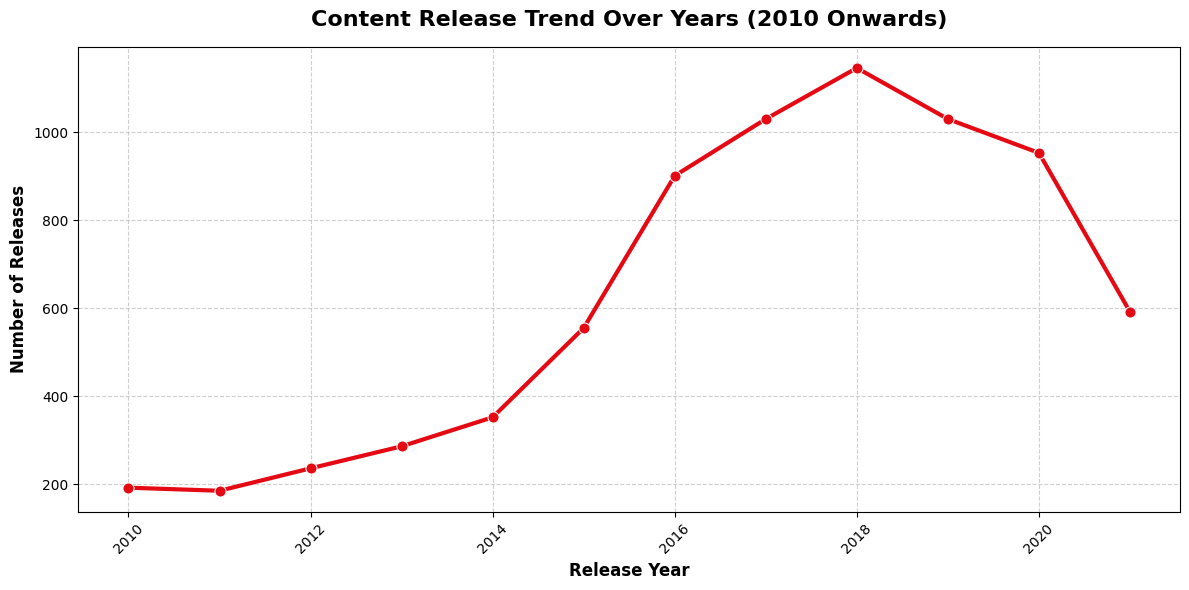

In [26]:
plt.figure(figsize=(12, 6))
yearly_trend = df[df['release_year'] >= 2010]['release_year'].value_counts().sort_index()

sns.lineplot(x=yearly_trend.index, y=yearly_trend.values, marker='o', color='#e50914', linewidth=3, markersize=8)

plt.title('Content Release Trend Over Years (2010 Onwards)', fontsize=16, weight='bold', pad=15)
plt.xlabel('Release Year', fontsize=12, weight='bold')
plt.ylabel('Number of Releases', fontsize=12, weight='bold')

# ضبط المحور الأفقي ليعرض السنوات بشكل صحيح بدون أرقام عشرية
plt.xticks(range(int(yearly_trend.index.min()), int(yearly_trend.index.max()) + 1, 2), rotation=45, fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

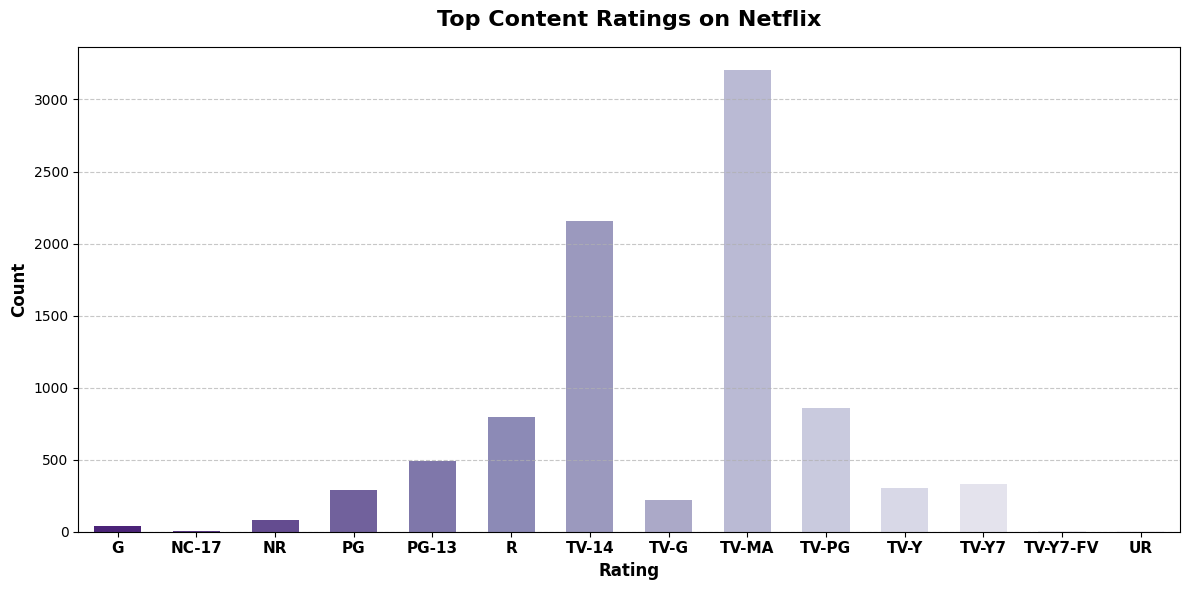

In [30]:
plt.figure(figsize=(12, 6))
top_ratings = df['rating'].value_counts()

# استخدام barplot مع تحكم أفضل بالشكل وعرض الأعمدة
sns.barplot(x=top_ratings.index, y=top_ratings.values, palette='Purples_r', hue=top_ratings.index, legend=False, width=0.6)

plt.title('Top Content Ratings on Netflix', fontsize=16, weight='bold', pad=15)
plt.xlabel('Rating', fontsize=12, weight='bold')
plt.ylabel('Count', fontsize=12, weight='bold')
plt.xticks(rotation=0, fontsize=11, weight='bold')
plt.yticks(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

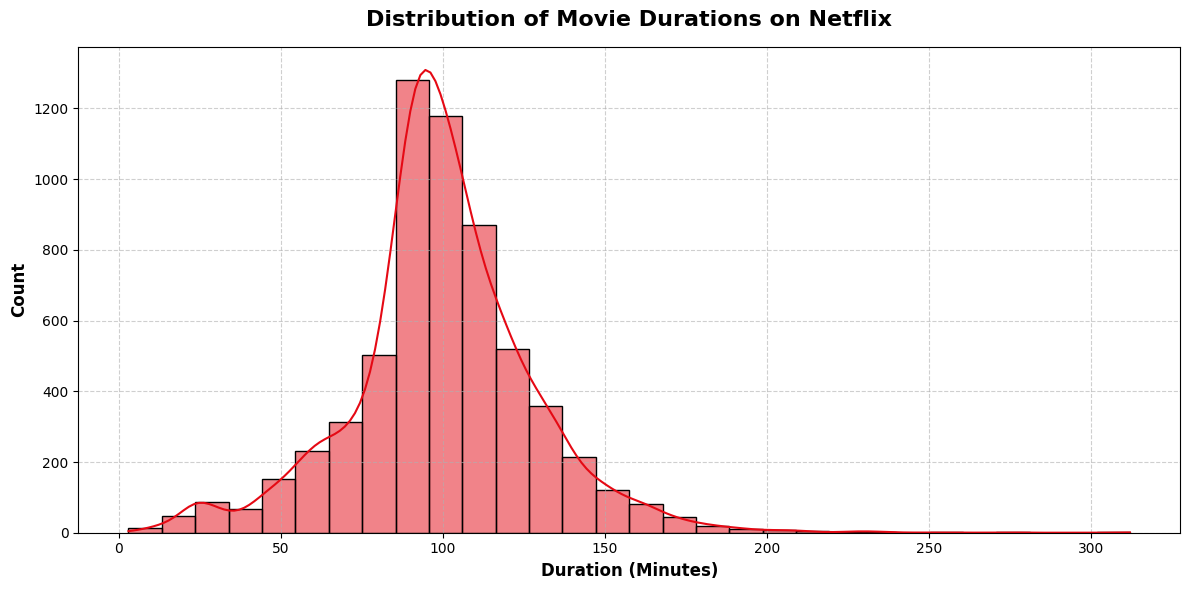

In [32]:
plt.figure(figsize=(12, 6))
movies_df = df[df['type'] == 'Movie']

sns.histplot(movies_df['duration_int'], bins=30, kde=True, color='#e50914')

plt.title('Distribution of Movie Durations on Netflix', fontsize=16, weight='bold', pad=15)
plt.xlabel('Duration (Minutes)', fontsize=12, weight='bold')
plt.ylabel('Count', fontsize=12, weight='bold')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

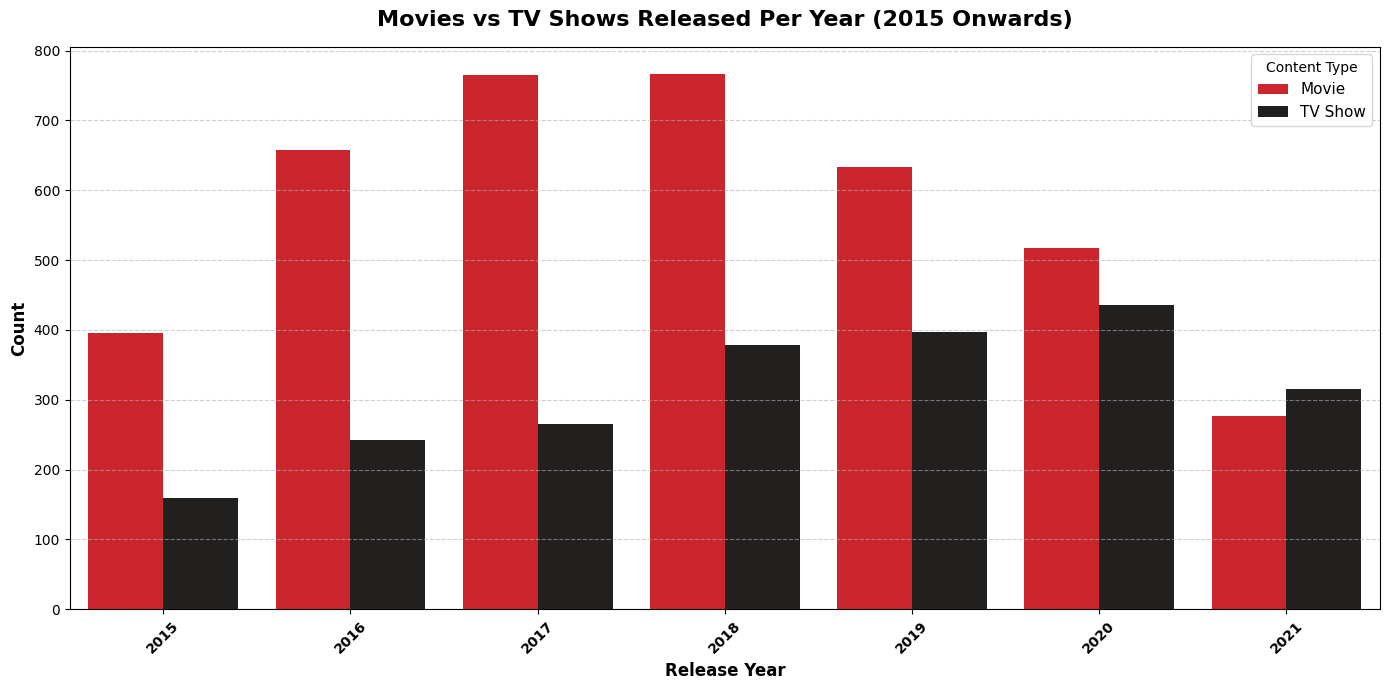

In [33]:
plt.figure(figsize=(14, 7))
recent_content = df[df['release_year'] >= 2015]

sns.countplot(x='release_year', hue='type', data=recent_content, palette=['#e50914', '#221f1f'])

plt.title('Movies vs TV Shows Released Per Year (2015 Onwards)', fontsize=16, weight='bold', pad=15)
plt.xlabel('Release Year', fontsize=12, weight='bold')
plt.ylabel('Count', fontsize=12, weight='bold')
plt.xticks(rotation=45, fontsize=10, weight='bold')
plt.legend(title='Content Type', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

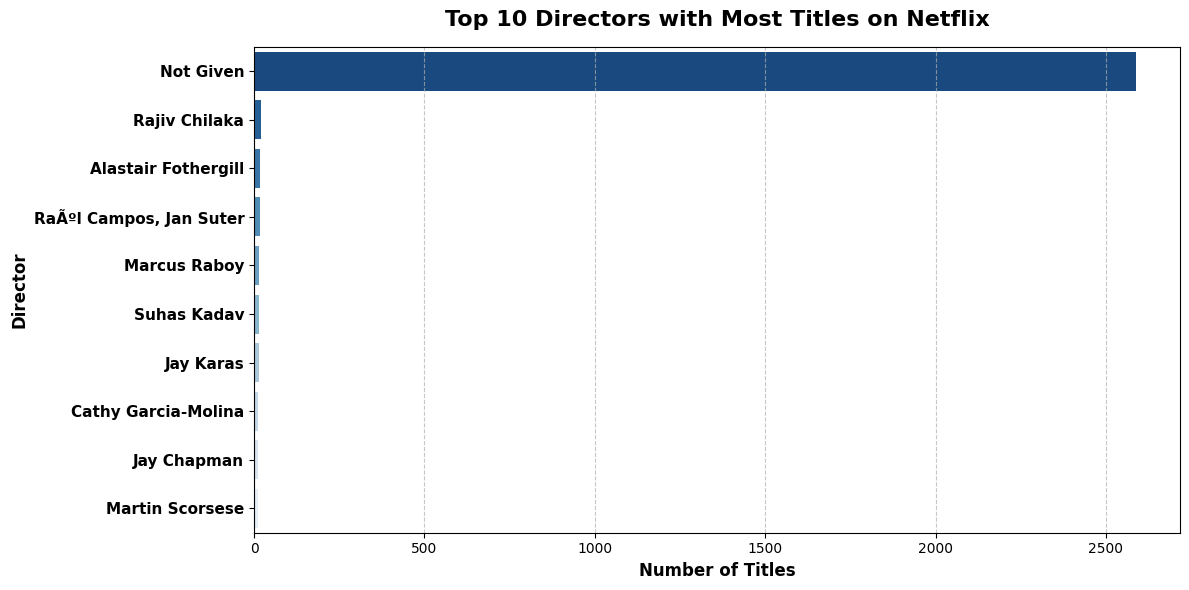

In [34]:
plt.figure(figsize=(12, 6))
top_directors = df[df['director'] != 'Unknown']['director'].value_counts().head(10)

sns.barplot(x=top_directors.values, y=top_directors.index, palette='Blues_r', hue=top_directors.index, legend=False)

plt.title('Top 10 Directors with Most Titles on Netflix', fontsize=16, weight='bold', pad=15)
plt.xlabel('Number of Titles', fontsize=12, weight='bold')
plt.ylabel('Director', fontsize=12, weight='bold')
plt.xticks(fontsize=10)
plt.yticks(fontsize=11, weight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()